# 21. Fixed-60-day full-feature three-day trajectory benchmark

User-confirmed rule: all model fitting must remain inside one fixed 60-day date interval. March 1-April 29, 2020 is exactly 60 calendar days. Fit on April 30. May evaluation never enters parameter training. Re-fitting identical complete data is redundant, so this experiment fits once per horizon. Predictor values can update at each May forecast origin. This is not one multiweek forecast issued on April 30, and not a sliding 60-day retraining experiment.

Include all 34 usable candidate columns before training-only identification checks, plus ZIP fixed effects. Static population/density/commuting attributes are absorbed by ZIP FE, audit fields are not predictors, and exact duplicate representations are omitted by design. No predictive feature selection. Fourteen warmup days stay inside the interval, leaving 45/44/43 usable origins for horizons 1/2/3. Sparse history resets March 1. Month effects for May cannot be learned from March-April.

585 fixed regions and May 1-28 forecast origins yield 16,380 region-origin trajectories and 49,140 target values. Targets remain raw daily recorded-onset counts, not a three-day moving average. This is exploratory historical replay using later-developed cohort/feature definitions and retrospective onset history. It does not simulate reporting delays.


In [1]:
"""Overall three-day trajectory evaluation with a FIXED 60-calendar-day training interval."""
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd

GROUPS={
 'core_history':['cases_today','cases_lag_1','cases_lag_7','cases_lag_14'],
 'rolling_level':['cases_mean_7d','cases_mean_14d'],
 'volatility':['case_std_7d','case_std_14d'],
 'dynamics':['case_acceleration','case_jerk'],
 'local_rates':['case_rate_today_per_100k','case_rate_7d_per_100k','case_rate_14d_per_100k'],
 'sparse_history':['days_since_last_observed_case_censored','no_previous_observed_case'],
 'pressure':['nj_covid_pressure_7d','nj_covid_pressure_14d'],
 'month':[f'target_month_{k}' for k in range(2,13)],
 'weekday':[f'target_weekday_{k}' for k in range(2,8)]}

def run_fixed60(source, cohort_file, output):
    source,output=Path(source),Path(output);output.mkdir(parents=True,exist_ok=True)
    ids=pd.read_csv(cohort_file,dtype={'zip':str})['zip'].to_numpy(dtype='U5')
    numeric=sum([v for k,v in GROUPS.items() if k not in ['month','weekday','sparse_history']],[])
    columns=['zip','date','pressure_definition']+numeric
    if source.read_bytes()[:7]==b'version':raise ValueError('Input is a Git LFS pointer, not data. Download its contents or use the saved input snapshot.')
    p=pd.read_csv(source,usecols=columns,dtype={'zip':str},parse_dates=['date'])
    p=p.loc[p.zip.isin(ids)&p.date.between('2020-03-01','2020-05-31')].copy()
    assert len(ids)==585 and not p.duplicated(['zip','date']).any()
    assert p.pressure_definition.eq('valid_population_nj_origins_renormalized_v2').all()
    dates=pd.date_range('2020-03-01','2020-05-31')
    def matrix(c):return p.pivot(index='zip',columns='date',values=c).reindex(index=ids,columns=dates).to_numpy(float)
    arrays={c:matrix(c) for c in numeric};counts=arrays['cases_today']
    # Reset sparse-history state at March 1, so no pre-interval cases enter training.
    last=np.full(len(ids),-1,dtype=int);gap=np.empty_like(counts);never=np.empty_like(counts)
    for t in range(len(dates)):
        last=np.where(counts[:,t]>0,t,last);never[:,t]=(last<0)
        gap[:,t]=np.where(last>=0,t-last,t+1)
    arrays['no_previous_observed_case']=never;arrays['days_since_last_observed_case_censored']=gap
    # Drop rows whose 14-day lag would reach before March 1. Training targets end April 29.
    end=int(dates.get_loc('2020-04-29'));assert end+1==60
    origins=np.flatnonzero((dates>=pd.Timestamp('2020-05-01'))&(dates<=pd.Timestamp('2020-05-28')))
    actual=np.stack([counts[:,origins+h] for h in (1,2,3)],axis=2) # region, origin, horizon
    features=sum(GROUPS.values(),[]);pred=np.empty_like(actual);coef=[];timing=[];omitted=[];maxdiff=0
    for hh,h in enumerate((1,2,3)):
        target=dates+pd.Timedelta(days=h)
        for k in range(2,13):arrays[f'target_month_{k}']=np.broadcast_to((target.month==k).astype(float),counts.shape)
        for k in range(2,8):arrays[f'target_weekday_{k}']=np.broadcast_to((target.dayofweek==k-1).astype(float),counts.shape)
        x=np.stack([arrays[f] for f in features],axis=2)
        train=np.arange(14,end-h+1)
        assert dates[train[0]]>=pd.Timestamp('2020-03-15') and dates[train[-1]+h]<=pd.Timestamp('2020-04-29')
        xt=x[:,train];yt=counts[:,train+h];xp=x[:,origins]
        assert np.isfinite(xt).all() and np.isfinite(xp).all()
        xm=xt.mean(axis=1);ym=yt.mean(axis=1);xc=xt-xm[:,None];yc=yt-ym[:,None]
        norms=np.sqrt((xc*xc).mean(axis=(0,1)));scale=np.where(norms>1e-10,norms,1)
        z=(xc/scale).reshape(-1,len(features));keep=[];q=[]
        for j,f in enumerate(features):
            if norms[j]<1e-10:
                omitted.append(dict(horizon=h,feature=f,reason='Constant within region in fixed training interval, absorbed by ZIP FE'));continue
            v=z[:,j].copy()
            for _ in range(2):
                for u in q:v-=u*(u@v)
            length=np.linalg.norm(v)
            if length<=1e-7*np.sqrt(len(v)):
                omitted.append(dict(horizon=h,feature=f,reason='Training-only exact linear dependence'));continue
            keep.append(j);q.append(v/length)
        b=np.linalg.lstsq(z[:,keep],yc.ravel(),rcond=None)[0]/scale[keep]
        alpha=ym-xm[:,keep]@b
        pred[:,:,hh]=np.einsum('ntp,p->nt',xp[:,:,keep],b)+alpha[:,None]
        # Prediction equivalence with the explicit centered least-squares formulation.
        direct=np.linalg.lstsq(xc[:,:,keep].reshape(-1,len(keep)),yc.ravel(),rcond=None)[0]
        dp=np.einsum('ntp,p->nt',xp[:,:,keep],direct)+(ym-xm[:,keep]@direct)[:,None]
        diff=float(np.max(np.abs(dp-pred[:,:,hh])));maxdiff=max(maxdiff,diff)
        assert np.allclose(dp,pred[:,:,hh],atol=1e-6,rtol=1e-6)
        for j,value in zip(keep,b):coef.append(dict(horizon=h,feature=features[j],coefficient=value))
        timing.append(dict(horizon=h,fit_date='2020-04-30',fixed_interval_start='2020-03-01',fixed_interval_end='2020-04-29',interval_calendar_days=60,training_origin_start=str(dates[train[0]].date()),training_origin_end=str(dates[train[-1]].date()),latest_training_target=str(dates[train[-1]+h].date()),usable_training_origins=len(train),regions=len(ids),estimated_slopes=len(keep),candidate_columns=len(features)))
    clipped=np.maximum(pred,0);errors=clipped-actual
    rows=[]
    for hh,h in enumerate((1,2,3)):
        e=errors[:,:,hh];rows.append(dict(scope='pooled_region_origin',horizon=str(h),observations=e.size,MAE=float(np.abs(e).mean()),RMSE=float(np.sqrt((e*e).mean())),bias=float(e.mean()),mean_actual=float(actual[:,:,hh].mean())))
    rows.append(dict(scope='pooled_region_origin',horizon='all_1_2_3',observations=errors.size,MAE=float(np.abs(errors).mean()),RMSE=float(np.sqrt((errors*errors).mean())),bias=float(errors.mean()),mean_actual=float(actual.mean())))
    slopes=(actual[:,:,2]-actual[:,:,0])/2;pslopes=(clipped[:,:,2]-clipped[:,:,0])/2
    trend=[]
    for threshold in [0.,.5,1.]:
        def classify(a):return np.where(a>threshold,1,np.where(a<-threshold,-1,0))
        truth,estimate=classify(slopes),classify(pslopes)
        for label,mask in [('all',np.ones_like(slopes,dtype=bool)),('actual_nonflat',truth!=0),('actual_flat',truth==0),('actual_all_three_zero',(actual==0).all(axis=2))]:
            trend.append(dict(slope_flat_threshold=threshold,subgroup=label,trajectory_count=int(mask.sum()),direction_agreement=float((truth[mask]==estimate[mask]).mean()) if mask.any() else None,slope_MAE=float(np.abs(pslopes[mask]-slopes[mask]).mean()) if mask.any() else None))
    confusion=[]
    for threshold in [0.,.5,1.]:
        t=np.where(slopes>threshold,1,np.where(slopes<-threshold,-1,0));est=np.where(pslopes>threshold,1,np.where(pslopes<-threshold,-1,0))
        for a in [-1,0,1]:
            for b in [-1,0,1]:confusion.append(dict(slope_flat_threshold=threshold,actual_direction=a,predicted_direction=b,count=int(((t==a)&(est==b)).sum())))
    # Shape check beyond end-to-end slope: compare the two consecutive daily movements.
    steps_a=np.sign(np.diff(actual,axis=2));steps_p=np.sign(np.diff(clipped,axis=2))
    shape=dict(trajectories=int(slopes.size),slope_MAE=float(np.abs(pslopes-slopes).mean()),slope_RMSE=float(np.sqrt(((pslopes-slopes)**2).mean())),two_step_exact_direction_agreement=float((steps_a==steps_p).all(axis=2).mean()),mean_three_point_MAE=float(np.abs(errors).mean()),primary_direction_rule='Signs of day3-minus-day1, exact zero classified flat. Threshold 0.5 and 1 cases/day are prespecified sensitivity summaries, not tuned choices.')
    pd.DataFrame(rows).to_csv(output/'overall_case_metrics.csv',index=False)
    pd.DataFrame(trend).to_csv(output/'overall_trajectory_metrics.csv',index=False)
    pd.DataFrame(confusion).to_csv(output/'direction_confusion_counts.csv',index=False)
    pd.DataFrame(timing).to_csv(output/'training_timing.csv',index=False)
    pd.DataFrame(coef).to_csv(output/'coefficients.csv',index=False)
    pd.DataFrame(omitted).to_csv(output/'unestimable_feature_log.csv',index=False)
    pd.DataFrame([(g,f) for g,fs in GROUPS.items() for f in fs],columns=['group','feature']).to_csv(output/'candidate_features.csv',index=False)
    # Aggregate plots are supplementary, not a substitute for pooled ZIP-level errors.
    total_actual=actual.sum(axis=0);total_pred=clipped.sum(axis=0);total_error=total_pred-total_actual
    totals=[]
    for t,origin in enumerate(dates[origins]):
        for hh,h in enumerate((1,2,3)):totals.append(dict(forecast_origin=origin,horizon=h,target_date=origin+pd.Timedelta(days=h),actual_total=total_actual[t,hh],predicted_total=total_pred[t,hh]))
    pd.DataFrame(totals).to_csv(output/'aggregate_trajectory_predictions.csv',index=False)
    p.to_csv(output/'input_snapshot.csv.gz',index=False)
    np.savez_compressed(output/'predictions.npz',raw_predictions=pred,actual_cases=actual,zip=ids,forecast_origins=dates[origins].to_numpy(),horizons=[1,2,3])
    protocol=dict(fixed_training_interval=['2020-03-01','2020-04-29'],calendar_days=60,fit_date='2020-04-30',retraining_during_may=False,reason='User confirmed one fixed 60-day date interval. Re-fitting the same complete data has identical parameters.',forecast_origins=['2020-05-01','2020-05-28'],historical_predictors='Updated through each forecast origin, but no May labels enter parameter fitting.',regions=len(ids),candidate_columns=len(features),region_FE=True,all_candidates_considered=True,predictive_feature_selection=False,warmup_days_within_interval=14,source=str(source),source_sha256=hashlib.sha256(source.read_bytes()).hexdigest(),source_definition='Retrospective onset counts, valid_population_nj_origins_renormalized_v2.',unseen_target_month='May-specific dummy never varies in training and is omitted. May has no estimated month-specific effect. Month levels encountered are logged; no future parameters are estimated.',static_features='Population, density and static commuting attributes absorbed by ZIP FE. Exact duplicate sums/velocity not separately represented.',sparse_history='Reset at fixed interval start. No pre-March case history used.',evaluation='Exploratory historical replay. Existing cohort/feature definitions used later data. No untouched-test or real-time reporting-delay claim.',trajectory='Three raw daily-count predictions from one origin; no 3-day smoothing of prediction targets.',shape_metrics=shape)
    (output/'protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')
    checks=dict(training_interval_exactly_60_calendar_days=True,all_training_targets_inside_fixed_interval=True,no_may_training_labels=True,training_feature_lookbacks_inside_interval=True,all_predictions_finite=bool(np.isfinite(pred).all()),horizons_share_same_region_origins=True,direct_OLS_max_difference=maxdiff,raw_predictions_saved=True,per_zip_score_tables_created=False)
    (output/'verification.json').write_text(json.dumps(checks,indent=2))
    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        figures=output/'figures';figures.mkdir(exist_ok=True)
        fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
        for hh,ax in enumerate(axes):
            ax.plot(dates[origins]+pd.Timedelta(days=hh+1),total_actual[:,hh],color='#64748b',label='Actual total')
            ax.plot(dates[origins]+pd.Timedelta(days=hh+1),total_pred[:,hh],color='#2563eb',label='Predicted total')
            ax.set_title(f'{hh+1}-day ahead');ax.tick_params(axis='x',rotation=30);ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
        axes[0].set_ylabel('Total recorded onset cases in 585 regions')
        fig.suptitle('Fixed March-April fit: May forecasts, aggregated across regions')
        fig.tight_layout();fig.savefig(figures/'01_overall_forecasts.png',dpi=250);plt.close(fig)
        fig,axes=plt.subplots(1,4,figsize=(14,4),sharey=True)
        chosen=['2020-05-01','2020-05-08','2020-05-15','2020-05-22']
        for ax,day in zip(axes,chosen):
            t=int(np.flatnonzero(dates[origins]==pd.Timestamp(day))[0])
            ax.plot([1,2,3],total_actual[t],marker='o',color='#64748b',label='Actual')
            ax.plot([1,2,3],total_pred[t],marker='o',color='#2563eb',label='Predicted')
            ax.set(title='Origin '+day,xticks=[1,2,3],xlabel='Days ahead');ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
        axes[0].set_ylabel('Total recorded onset cases')
        fig.suptitle('Three-day trajectories from four preselected forecast origins')
        fig.tight_layout();fig.savefig(figures/'02_same_origin_trajectories.png',dpi=250);plt.close(fig)
    except ImportError:print('Optional figures require matplotlib.')
    report='# Fixed-60-day full-candidate trajectory benchmark\n\n'
    report+='Training is restricted to March 1-April 29, 2020 (60 calendar days). Parameters fit once on April 30 and remain frozen throughout May. Daily predictor updates are allowed, but May labels never update parameters. Fourteen warmup days and horizon maturity leave 45/44/43 usable training origins for h=1/2/3, respectively. This is not 60 usable training pairs per horizon.\n\n'
    report+='All 34 candidate columns enter the design; training-only constant/dependent columns are logged, not removed by predictive selection. Static geography is absorbed by ZIP FE. May month effects are unestimable from March-April and are not learned. Both Pressure candidates enter the design.\n\n'
    report+='## Overall case metrics\n'+pd.DataFrame(rows).to_string(index=False)+'\n\n## Trajectory metrics\n'+pd.DataFrame(trend).to_string(index=False)+'\n\n'
    report+='These direction rates pool ZIP-origin trajectories and do not mean that the same proportion of ZIPs is accurate. Exact-flat and all-zero paths are reported separately. Threshold sensitivity is descriptive, not tuned. Aggregate curves can hide offsetting regional errors and are supplementary. No per-ZIP accuracy table is produced. Raw predictions remain available for verification.\n\n'
    report+='May primarily covers decline in this dataset. Results do not establish rising-wave or outbreak-warning performance. Historical replay uses later-developed feature definitions/cohort and retrospective onset history, not a prospective untouched test. No PR-AUC, warning lead time or residual Moran score is fabricated.\n'
    (output/'RESULTS.md').write_text(report,encoding='utf-8')
    print(pd.DataFrame(rows).to_string(index=False));print(pd.DataFrame(trend).to_string(index=False));print(output.resolve())
    return pd.DataFrame(rows),pd.DataFrame(trend),output


In [2]:
REPO = Path.cwd()
OUTPUT = REPO / 'fixed60_trajectory_outputs' / 'fixed60_20261027'
# Read completed overall results without fitting again.
display(pd.read_csv(OUTPUT / 'overall_case_metrics.csv'))
display(pd.read_csv(OUTPUT / 'overall_trajectory_metrics.csv'))
print((OUTPUT / 'RESULTS.md').read_text(encoding='utf-8'))


,scope,horizon,observations,MAE,RMSE,bias,mean_actual
0,pooled_region_origin,1,16380,0.847427,1.644652,0.512567,0.586142
1,pooled_region_origin,2,16380,0.970863,1.910649,0.666664,0.561600
2,pooled_region_origin,3,16380,1.124773,2.279238,0.839333,0.541514
3,pooled_region_origin,all_1_2_3,49140,0.981021,1.962175,0.672855,0.563085


,slope_flat_threshold,subgroup,trajectory_count,direction_agreement,slope_MAE,always_flat_direction_agreement,balanced_direction_accuracy
0,0.0,all,16380,0.354335,0.412099,0.655495,0.426890
1,0.0,actual_nonflat,5643,0.488038,0.882422,NaN,NaN
2,0.0,actual_flat,10737,0.284064,0.164913,NaN,NaN
3,0.0,actual_all_three_zero,8631,0.328351,0.123248,NaN,NaN
4,0.5,all,16380,0.804029,0.412099,0.886020,0.401280
5,0.5,actual_nonflat,1867,0.144081,1.516228,NaN,NaN
6,0.5,actual_flat,14513,0.888927,0.270060,NaN,NaN
7,0.5,actual_all_three_zero,8631,0.955162,0.123248,NaN,NaN
8,1.0,all,16380,0.922405,0.412099,0.952381,0.357686
9,1.0,actual_nonflat,780,0.047436,2.188309,NaN,NaN


# Fixed-60-day full-candidate trajectory benchmark

Training is restricted to March 1-April 29, 2020 (60 calendar days). Parameters fit once on April 30 and remain frozen throughout May. Daily predictor updates are allowed, but May labels never update parameters. Fourteen warmup days and horizon maturity leave 45/44/43 usable training origins for h=1/2/3, respectively. This is not 60 usable training pairs per horizon.

All 34 candidate columns enter the design; training-only constant/dependent columns are logged, not removed by predictive selection. Static geography is absorbed by ZIP FE. May month effects are unestimable from March-April and are not learned. Both Pressure candidates enter the design.

## Overall case metrics
               scope   horizon  observations      MAE     RMSE     bias  mean_actual
pooled_region_origin         1         16380 0.847427 1.644652 0.512567     0.586142
pooled_region_origin         2         16380 0.970863 1.910649 0.666664     0.561600
pooled_re

## Optional reproducible rerun

The saved input snapshot contains the exact required March-May feature inputs for this experiment, so the rerun does not depend on downloading a large Git LFS file. Source lineage is recorded in protocol.json. The following cell fits models again; skip it when reviewing the saved results. Output goes to a separate rerun folder.


In [3]:
case_metrics, trajectory_metrics, RERUN_FOLDER = run_fixed60(OUTPUT / 'input_snapshot.csv.gz', OUTPUT / 'common_regions.csv', REPO / 'fixed60_trajectory_outputs' / 'fixed60_20261027_rerun')
display(case_metrics)
display(trajectory_metrics)


               scope   horizon  observations      MAE     RMSE     bias  mean_actual
pooled_region_origin         1         16380 0.847427 1.644652 0.512567     0.586142
pooled_region_origin         2         16380 0.970863 1.910649 0.666664     0.561600
pooled_region_origin         3         16380 1.124773 2.279238 0.839333     0.541514
pooled_region_origin all_1_2_3         49140 0.981021 1.962175 0.672855     0.563085
 slope_flat_threshold              subgroup  trajectory_count  direction_agreement  slope_MAE
                  0.0                   all             16380             0.354335   0.412099
                  0.0        actual_nonflat              5643             0.488038   0.882422
                  0.0           actual_flat             10737             0.284064   0.164913
                  0.0 actual_all_three_zero              8631             0.328351   0.123248
                  0.5                   all             16380             0.804029   0.412099
           

,scope,horizon,observations,MAE,RMSE,bias,mean_actual
0,pooled_region_origin,1,16380,0.847427,1.644652,0.512567,0.586142
1,pooled_region_origin,2,16380,0.970863,1.910649,0.666664,0.561600
2,pooled_region_origin,3,16380,1.124773,2.279238,0.839333,0.541514
3,pooled_region_origin,all_1_2_3,49140,0.981021,1.962175,0.672855,0.563085


,slope_flat_threshold,subgroup,trajectory_count,direction_agreement,slope_MAE
0,0.0,all,16380,0.354335,0.412099
1,0.0,actual_nonflat,5643,0.488038,0.882422
2,0.0,actual_flat,10737,0.284064,0.164913
3,0.0,actual_all_three_zero,8631,0.328351,0.123248
4,0.5,all,16380,0.804029,0.412099
5,0.5,actual_nonflat,1867,0.144081,1.516228
6,0.5,actual_flat,14513,0.888927,0.270060
7,0.5,actual_all_three_zero,8631,0.955162,0.123248
8,1.0,all,16380,0.922405,0.412099
9,1.0,actual_nonflat,780,0.047436,2.188309


## Overall results and graphs

Pooled metrics average errors across region-origin trajectories, not percentages of ZIPs that are correct. The aggregate plots sum predictions across regions and can conceal offsetting errors. The same-origin figure shows three predictions issued together. Trend slope = (day 3 minus day 1)/2, in cases/day. Strict sign accuracy is primary descriptive output; tolerance 0.5 and 1 are prespecified sensitivity summaries. Always-flat and balanced direction summaries help identify inflated accuracy due to flat/zero trajectories. No threshold is selected from these scores.

Read overall_case_metrics.csv, overall_trajectory_metrics.csv, direction_confusion_counts.csv and RESULTS.md first. Training timing, coefficients, unestimable-feature logs and raw predictions support reproducibility. No per-ZIP accuracy table is generated.


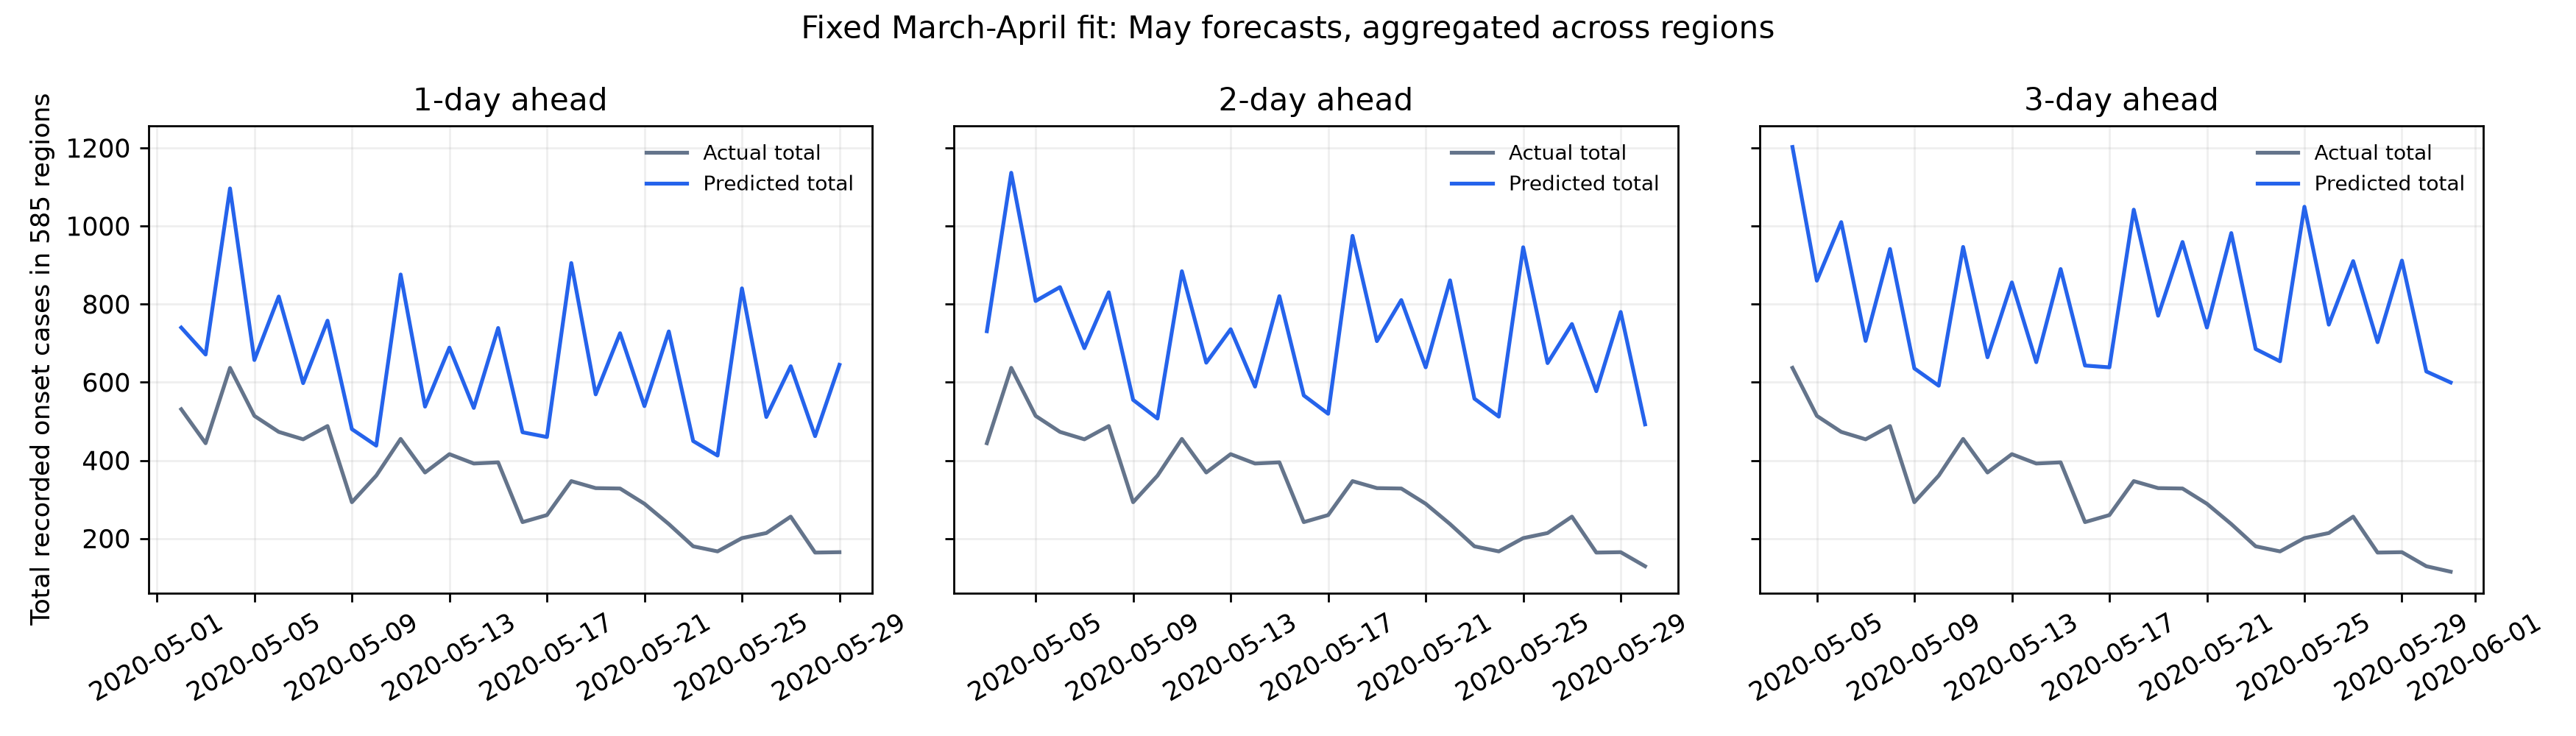

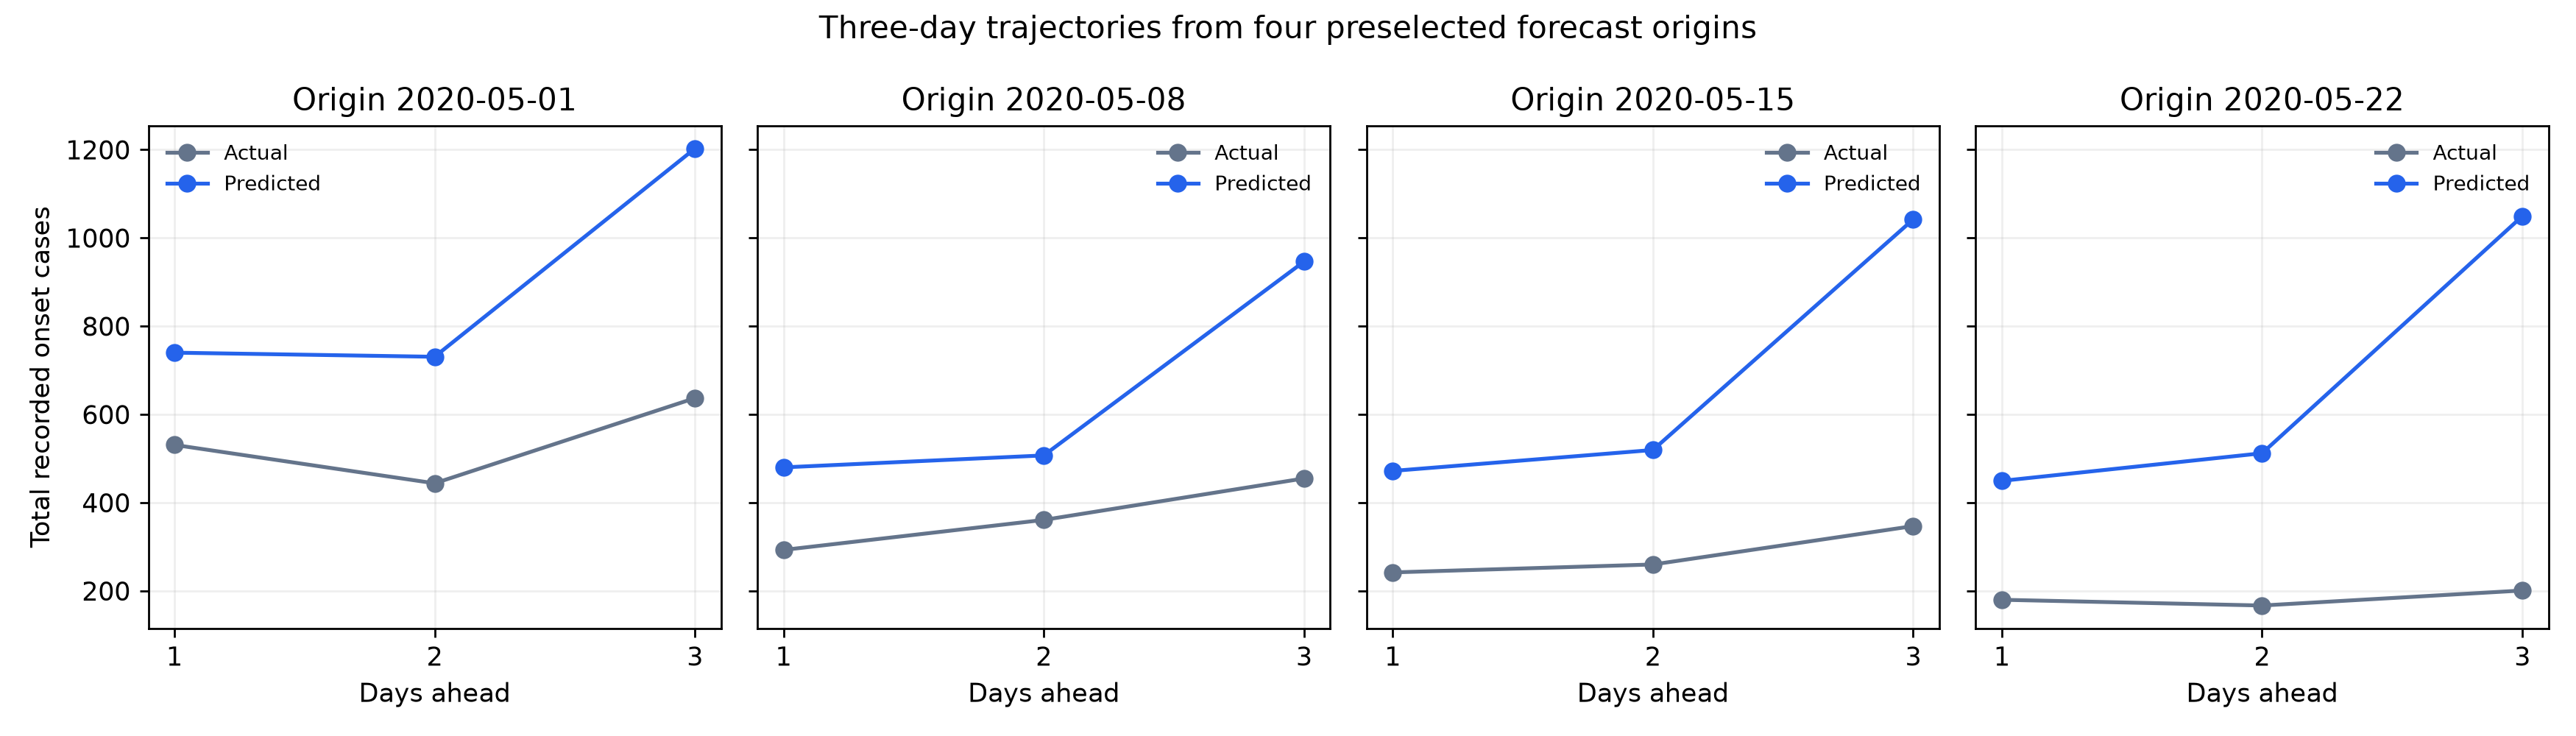

In [4]:
from IPython.display import Image, display
for name in ['01_overall_forecasts.png','02_same_origin_trajectories.png']:
    p = OUTPUT / 'figures' / name
    if p.exists():
        display(Image(filename=str(p)))
